# Session 5 — A classical machine-learning baseline for MILK10k

**Task.** From the dermoscopic (and optionally the clinical) photograph of a skin lesion, predict
`diagnosis_1`: **Benign / Indeterminate / Malignant**. This notebook builds the *baseline* every later
model has to beat: hand-crafted colour and texture features (Sessions 2 and 4) fed to classical
scikit-learn models, evaluated on the leak-free lesion-level splits from Session 3.

**Method in one paragraph.** Seven feature sets × six models (42 configurations) are compared by 5-fold cross-validation
*on the training split only*; the best configuration is tuned with a small grid search, refit on the
training split, checked on the validation split, and finally scored **once** on the test split with a
bootstrap confidence interval. Features are scaled with a `StandardScaler` that lives *inside* the
pipeline, so every fold (and the validation/test splits) is scaled with training-fold statistics only.

| Decision | Choice | Why |
|---|---|---|
| Unit of analysis | one row per **lesion** | a lesion has two photos; splitting by image would leak the lesion across train/test (Session 3) |
| Splits | `artifacts/splits/{train,val,test}.csv`, seed 42, 70 / 15 / 15 | already verified lesion-disjoint and stratified |
| Metric | **macro-F1** | accuracy rewards predicting "Malignant" for everything (69 % of lesions); macro-F1 weighs the rare *Indeterminate* class as much as the others |
| Selection | mean CV macro-F1 on **train** | the validation split holds only 17 Indeterminate lesions, too few to choose a model on |
| Imbalance | `class_weight="balanced"` where the model supports it | cheapest correction; no resampling that could touch validation data |

In [1]:
# --- setup: find the repo root from wherever the notebook is opened -----------
import sys, json, time, warnings
from pathlib import Path

ROOT = Path.cwd().resolve()
while not (ROOT / "src" / "milk10k").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import milk10k as mk
from milk10k import features as F

np.set_printoptions(precision=3, suppress=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, classification_report,
                             f1_score)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_validate
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

from milk10k.metrics import DEFAULT_COST, expected_cost

SEED = mk.config.SEED
CLASSES = F.CLASSES
BLUE, ORANGE, AQUA = mk.BLUE, mk.ORANGE, mk.AQUA
OUT = mk.config.ARTIFACT_DIR / "session05"
OUT.mkdir(parents=True, exist_ok=True)

## 1. Data: lesion-level splits and cached features

`load_lesion_splits()` returns one row per lesion with the ids of its dermoscopic and clinical photo.
`feature_table()` extracts every feature for all 10,480 images once (≈ 20 s) and caches them in
`artifacts/features/features.npz`, so re-running the notebook is instant.

In [2]:
frames = F.load_lesion_splits()
meta = F.metadata_features(frames)                        # categories + median from TRAIN only
ids = pd.concat([f[c] for f in frames.values() for c in ("derm_id", "clinical_id")])
feats = F.feature_table(ids, cache=F.FEATURE_DIR / "features.npz")
y = {k: v["diagnosis_1"].to_numpy() for k, v in frames.items()}

counts = pd.DataFrame({k: pd.Series(v).value_counts() for k, v in y.items()}).loc[CLASSES]
counts.loc["total"] = counts.sum()
print(f"features: {feats.shape[1]} per image, {feats.shape[0]:,} images, "
      f"{int(feats.isna().sum().sum())} missing")
counts

features: 37 per image, 10,480 images, 0 missing


,train,val,test
Benign,1058,213,212
Indeterminate,89,17,17
Malignant,2595,519,520
total,3742,749,749


The classes are strongly imbalanced (≈ 70 % Malignant, 28 % Benign, **2 % Indeterminate**), and the
validation/test splits contain only 17 Indeterminate lesions each. Two consequences are kept in mind
throughout: a majority-class model already scores 69 % accuracy, and any macro-F1 difference of a few
hundredths is within noise because one Indeterminate lesion more or less moves that class's F1 a lot.

In [3]:
groups = pd.DataFrame({
    "group": list(F.FEATURE_GROUPS),
    "n": [len(v) for v in F.FEATURE_GROUPS.values()],
    "what it measures": ["mean and std of R, G, B (overall tint and contrast)",
                         "8-bin intensity histogram per channel (colour distribution, e.g. dark pigment vs red vessels)",
                         "edge density (Sobel), roughness (local variance), sharpness (Laplacian variance)",
                         "mean/std of saturation and value (colour purity, brightness)"],
}).set_index("group")
sets = pd.DataFrame({"feature set": list(F.FEATURE_SETS),
                     "n features": [F.build_matrix(n, frames["val"], feats, meta["val"]).shape[1]
                                    for n in F.FEATURE_SETS]}).set_index("feature set")
display(groups); display(sets)

,n,what it measures
group,,
color_stats,6,"mean and std of R, G, B (overall tint and cont..."
color_hist,24,8-bin intensity histogram per channel (colour ...
texture,3,"edge density (Sobel), roughness (local varianc..."
hsv,4,mean/std of saturation and value (colour purit...


,n features
feature set,
colour stats (6),6
colour stats + histogram (30),30
Session 5 set (33),33
33 + HSV (37),37
33 + metadata,42
derm + clinical (66),66
metadata only,9


## 2. Feature sets × models

Every combination is scored two ways: **5-fold stratified CV macro-F1 on the training lesions** (mean ± std
over folds, the selection criterion) and macro-F1 of a single fit on train evaluated on **validation**
(a sanity check, not used to choose). Each model sits behind a `StandardScaler` in one `Pipeline`.
The test split is not touched in this section.

In [4]:
MODELS = {
    "majority":            lambda: DummyClassifier(strategy="most_frequent"),
    "logistic regression": lambda: LogisticRegression(max_iter=2000, class_weight="balanced"),
    "kNN (k=15)":          lambda: KNeighborsClassifier(n_neighbors=15),
    "random forest":       lambda: RandomForestClassifier(n_estimators=300, min_samples_leaf=3,
                                      class_weight="balanced", n_jobs=1, random_state=SEED),
    "gradient boosting":   lambda: HistGradientBoostingClassifier(learning_rate=0.05, max_iter=200,
                                      class_weight="balanced", random_state=SEED),
    "SVM (RBF)":           lambda: SVC(class_weight="balanced"),
}
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)

def pipeline(model_name):
    return Pipeline([("scale", StandardScaler()), ("model", MODELS[model_name]())])

X = {name: {k: F.build_matrix(name, frames[k], feats, meta[k]) for k in frames}
     for name in F.FEATURE_SETS}

t0 = time.perf_counter()
rows = []
for fs in F.FEATURE_SETS:
    for m in MODELS:
        res = cross_validate(pipeline(m), X[fs]["train"], y["train"], cv=cv,
                             scoring="f1_macro", n_jobs=5)
        fitted = pipeline(m).fit(X[fs]["train"], y["train"])
        rows.append({"feature set": fs, "model": m,
                     "cv_f1": res["test_score"].mean(), "cv_std": res["test_score"].std(),
                     "val_f1": f1_score(y["val"], fitted.predict(X[fs]["val"]), average="macro")})
grid = pd.DataFrame(rows)
grid.to_csv(OUT / "feature_model_grid.csv", index=False)
print(f"{len(grid)} configurations in {time.perf_counter() - t0:.0f} s")

42 configurations in 91 s


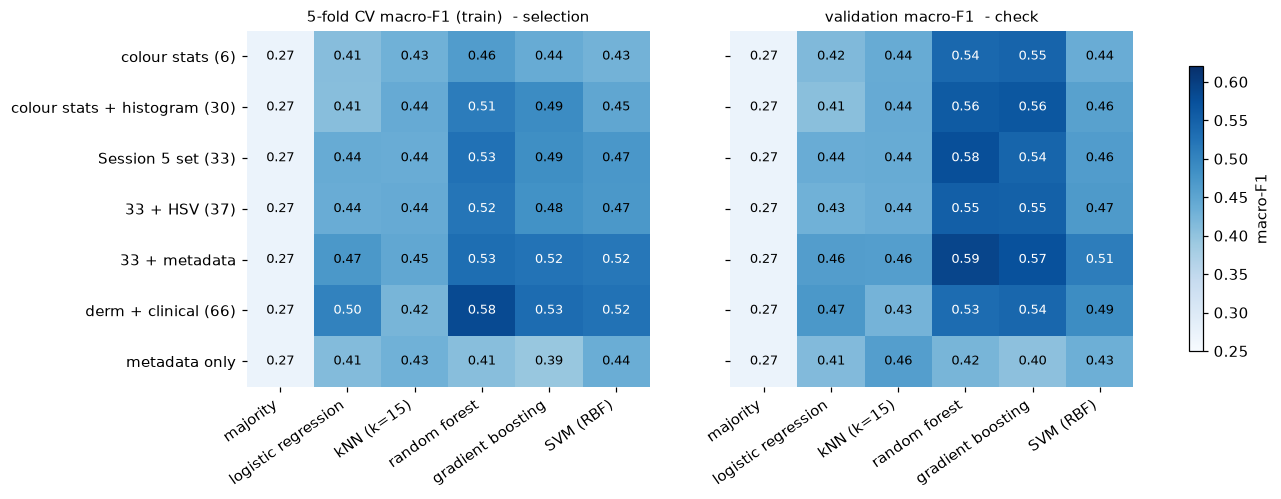

,feature set,model,cv_f1,cv_std,val_f1
1,derm + clinical (66),random forest,0.582,0.043,0.534
2,derm + clinical (66),gradient boosting,0.534,0.055,0.541
3,33 + metadata,random forest,0.531,0.018,0.589
4,Session 5 set (33),random forest,0.526,0.025,0.575
5,derm + clinical (66),SVM (RBF),0.525,0.016,0.488
6,33 + metadata,gradient boosting,0.525,0.023,0.573
7,33 + HSV (37),random forest,0.520,0.028,0.553
8,33 + metadata,SVM (RBF),0.518,0.023,0.509


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
for ax, col, title in zip(axes, ["cv_f1", "val_f1"], ["5-fold CV macro-F1 (train)  - selection", "validation macro-F1  - check"]):
    pv = grid.pivot(index="feature set", columns="model", values=col).loc[list(F.FEATURE_SETS), list(MODELS)]
    im = ax.imshow(pv.to_numpy(), cmap="Blues", vmin=0.25, vmax=0.62, aspect="auto")
    ax.set_xticks(range(pv.shape[1]), pv.columns, rotation=35, ha="right")
    ax.set_yticks(range(pv.shape[0]), pv.index)
    for i in range(pv.shape[0]):
        for j in range(pv.shape[1]):
            v = pv.iat[i, j]
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8.5,
                    color="white" if v > 0.5 else "black")
    ax.set_title(title, fontsize=10)
    ax.spines[:].set_visible(False)
fig.colorbar(im, ax=axes, shrink=0.8, label="macro-F1")
plt.show()

top = grid.sort_values("cv_f1", ascending=False).head(8).round(3).reset_index(drop=True)
top.index += 1
top

In [6]:
best = grid.sort_values("cv_f1", ascending=False).iloc[0]
best_fs, best_model = best["feature set"], best["model"]
same33 = grid[(grid["feature set"] == "Session 5 set (33)")].set_index("model")
meta_only = grid[(grid["feature set"] == "metadata only")].set_index("model")

print(f"best by CV: {best_model} on '{best_fs}'  CV {best.cv_f1:.3f} ± {best.cv_std:.3f}   val {best.val_f1:.3f}")
print(f"best model family on the plain 33 image features: "
      f"{same33.cv_f1.drop('majority').idxmax()}  CV {same33.cv_f1.drop('majority').max():.3f}")
print(f"metadata alone (age/sex/site), best model: {meta_only.cv_f1.idxmax()}  CV {meta_only.cv_f1.max():.3f}   "
      f"- majority: {same33.loc['majority','cv_f1']:.3f}")

best by CV: random forest on 'derm + clinical (66)'  CV 0.582 ± 0.043   val 0.534
best model family on the plain 33 image features: random forest  CV 0.526
metadata alone (age/sex/site), best model: SVM (RBF)  CV 0.436   - majority: 0.273


### Reading the grid

* **Tree ensembles lead.** Random forest is the best or tied-best model on every image feature set, gradient boosting is close behind,
  and kNN, logistic regression and the RBF-SVM trail. The signal is non-linear and unevenly scaled (histogram bins that are almost always
  0, heavy-tailed texture values), which trees handle without help.
* **Features add up slowly.** With the forest, going from 6 colour statistics (CV 0.46) to adding the colour histogram (0.51) and the three texture
  features (0.53) buys about +0.07 in total. HSV statistics add nothing (0.52).
* **The clinical photograph helps in CV, but not reliably.** Adding the clinical image's 33 features lifts the cross-validated forest to
  0.58 and also helps logistic regression, boosting and the SVM by 0.04 – 0.06. But the fold-to-fold spread is ±0.04, and on the validation
  split the same forest *drops* (0.53 vs 0.58 with dermoscopy alone). Treat it as a small, unconfirmed gain.
* **Age, sex and body site carry some signal, but not much on top of the image.** Metadata alone beats the majority model
  (CV 0.44 vs 0.27), yet adding it to the forest changes nothing (0.531 vs 0.526); it helps the linear model and the SVM a little.
  It is a legitimate input (a clinician knows it), but it also partly encodes how lesions came to be in the study (referral, biopsy), so it is
  kept as an option rather than a requirement.
* **No configuration is clearly best.** The top four rows of the table are within one standard deviation of each other; the choice
  below follows the rule set in advance (highest CV mean), not a claim that it is truly better.

## 3. Tune the winning model family

A small grid search (same 5 folds, same metric, training split only) on the best feature set.
The grids are deliberately modest: with 89 Indeterminate training lesions, a wide search would mostly
fit fold noise.

In [7]:
GRIDS = {
    "random forest":       {"model__min_samples_leaf": [1, 3, 5], "model__max_features": ["sqrt", 0.5]},
    "gradient boosting":   {"model__learning_rate": [0.03, 0.1], "model__max_leaf_nodes": [8, 31],
                            "model__l2_regularization": [0.0, 1.0]},
    "SVM (RBF)":           {"model__C": [0.3, 1, 3, 10], "model__gamma": ["scale", 0.01]},
    "logistic regression": {"model__C": [0.01, 0.1, 1, 10]},
    "kNN (k=15)":          {"model__n_neighbors": [5, 15, 31, 61]},
}

def tune(model_name, fs):
    gs = GridSearchCV(pipeline(model_name), GRIDS[model_name], scoring="f1_macro", cv=cv, n_jobs=5)
    return gs.fit(X[fs]["train"], y["train"])

def val_f1(est, fs):
    return f1_score(y["val"], est.predict(X[fs]["val"]), average="macro")

t0 = time.perf_counter()
gs = tune(best_model, best_fs)
tuned = {"best": {"fs": best_fs, "model": best_model, "search": gs, "estimator": gs.best_estimator_}}
untuned_cv = grid.query("`feature set` == @best_fs and model == @best_model").cv_f1.iloc[0]
print(f"{best_model} on '{best_fs}':  untuned CV {untuned_cv:.3f}  ->  tuned CV {gs.best_score_:.3f}   "
      f"val {val_f1(gs.best_estimator_, best_fs):.3f}   {gs.best_params_}")
print(f"{time.perf_counter() - t0:.0f} s")

random forest on 'derm + clinical (66)':  untuned CV 0.582  ->  tuned CV 0.582   val 0.568   {'model__max_features': 'sqrt', 'model__min_samples_leaf': 5}
25 s


## 4. Final evaluation — the test split, once

The chosen configuration and the course-recipe forest (33 features, untuned) are refit on the **training split** (the same data every later model sees, so the Session 6
scoreboard is apples to apples) and scored on the test split a single time. The confidence interval is a
percentile bootstrap over the 749 test lesions (2,000 resamples). The majority-class model is the floor.

In [8]:
def bootstrap_ci(y_true, y_pred, n=2000, seed=SEED):
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(y_true), (n, len(y_true)))
    f = [f1_score(y_true[i], y_pred[i], average="macro") for i in idx]
    return np.percentile(f, [2.5, 97.5])

def final_row(name, est, fs):
    pv, pt = est.predict(X[fs]["val"]), est.predict(X[fs]["test"])
    lo, hi = bootstrap_ci(y["test"], pt)
    return {"model": name, "features": fs,
            "val macro-F1": f1_score(y["val"], pv, average="macro"),
            "test macro-F1": f1_score(y["test"], pt, average="macro"),
            "95% CI": f"[{lo:.3f}, {hi:.3f}]",
            "test accuracy": accuracy_score(y["test"], pt),
            "Malignant recall": ((pt == "Malignant") & (y["test"] == "Malignant")).sum() / (y["test"] == "Malignant").sum(),
            "cost / lesion": expected_cost(y["test"], pt)}, pt

maj = pipeline("majority").fit(X["Session 5 set (33)"]["train"], y["train"])
forest33 = pipeline("random forest").fit(X["Session 5 set (33)"]["train"], y["train"])   # the Session 5 recipe, untuned
final = {}
for name, est, fs in [("majority class", maj, "Session 5 set (33)"),
                      ("random forest, course recipe", forest33, "Session 5 set (33)"),
                      (f"{tuned['best']['model']}, tuned  [CHOSEN]", tuned["best"]["estimator"], tuned["best"]["fs"])]:
    final[name] = final_row(name, est, fs)
table = pd.DataFrame([r for r, _ in final.values()]).set_index("model")
table.round(3)

,features,val macro-F1,test macro-F1,95% CI,test accuracy,Malignant recall,cost / lesion
model,,,,,,,
majority class,Session 5 set (33),0.273,0.273,"[0.266, 0.280]",0.694,1.000,0.397
"random forest, course recipe",Session 5 set (33),0.575,0.528,"[0.452, 0.597]",0.728,0.823,6.126
"random forest, tuned [CHOSEN]",derm + clinical (66),0.568,0.536,"[0.472, 0.601]",0.744,0.817,6.126


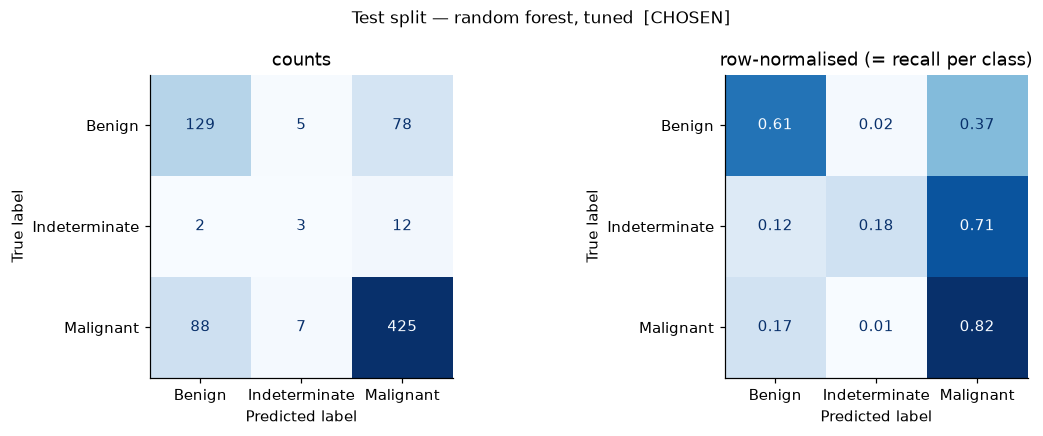

,precision,recall,f1-score,support
Benign,0.589,0.608,0.599,212.0
Indeterminate,0.200,0.176,0.188,17.0
Malignant,0.825,0.817,0.821,520.0
macro avg,0.538,0.534,0.536,749.0


In [9]:
chosen_name = [k for k in final if "CHOSEN" in k][0]
chosen_pred = final[chosen_name][1]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay.from_predictions(y["test"], chosen_pred, labels=CLASSES, ax=axes[0],
                                        cmap="Blues", colorbar=False)
ConfusionMatrixDisplay.from_predictions(y["test"], chosen_pred, labels=CLASSES, ax=axes[1],
                                        normalize="true", values_format=".2f", cmap="Blues", colorbar=False)
axes[0].set_title("counts"); axes[1].set_title("row-normalised (= recall per class)")
for ax in axes: ax.grid(False)
fig.suptitle(f"Test split — {chosen_name}", fontsize=11)
plt.tight_layout(); plt.show()

report = pd.DataFrame(classification_report(y["test"], chosen_pred, labels=CLASSES,
                                            output_dict=True, zero_division=0)).T
report.loc[CLASSES + ["macro avg"], ["precision", "recall", "f1-score", "support"]].round(3)

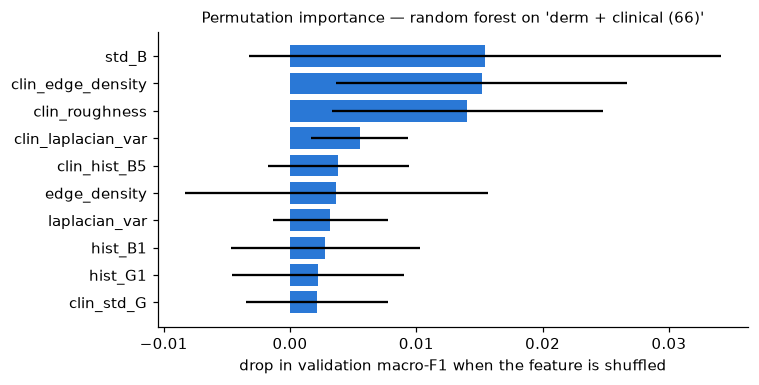

In [10]:
fs_best = tuned["best"]["fs"]
perm = permutation_importance(tuned["best"]["estimator"], X[fs_best]["val"], y["val"],
                              scoring="f1_macro", n_repeats=10, random_state=SEED, n_jobs=5)
cols = F.matrix_columns(fs_best, meta["val"])
imp = pd.Series(perm.importances_mean, index=cols).sort_values(ascending=False).head(10)
err = pd.Series(perm.importances_std, index=cols)[imp.index]
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.barh(imp.index[::-1], imp.values[::-1], xerr=err.values[::-1], color=BLUE)
ax.set_xlabel("drop in validation macro-F1 when the feature is shuffled")
ax.set_title(f"Permutation importance — {tuned['best']['model']} on '{fs_best}'", fontsize=10)
plt.tight_layout(); plt.show()

### What the baseline says

* **Headline.** The chosen forest scores **test macro-F1 0.536** (95 % bootstrap CI 0.47 – 0.60) against 0.273 for always predicting
  Malignant. Accuracy is 74.4 % against 69.4 % for that trivial rule, so the extra information is real but modest.
  Validation (0.568) and CV (0.582) agree within the interval; the spread between them is the noise of a 749-lesion split.
* **Tuning changed nothing.** Searching `min_samples_leaf` and `max_features` (6 settings, 5-fold CV) moved the CV score by less than 0.001;
  the forest was already near its plateau, so the remaining error is in the features, not the hyper-parameters.
* **The extra feature set does not matter at the headline level.** The course-recipe forest on the 33 dermoscopic features alone gets test
  macro-F1 0.528 (CI 0.45 – 0.60), statistically indistinguishable from the chosen configuration. That 33-feature forest is the like-for-like
  number for the Session 6 MLP, which sees the same 33 inputs; the 66-feature forest is the best baseline to beat overall.
* **Per class.** Malignant F1 0.82, Benign 0.60, Indeterminate 0.19: the forest finds 3 of 17 Indeterminate lesions. Macro-F1 averages these,
  so one Indeterminate lesion more or less moves it by roughly ±0.01.
* **The error that matters.** 88 of 520 malignant lesions (17 %) are predicted Benign. Under the cost matrix from Part A (a missed
  malignancy costs 50, a needless work-up 1) the forest costs 6.13 per lesion, **worse** than the trivial "always Malignant" rule at 0.40.
  Macro-F1 improved over the trivial baseline, but this model is not safe as a screening tool, and a deployed version would need a
  decision threshold that favours Malignant recall.
* **What drives it.** Permutation importance is flat and noisy (error bars cross zero): texture of the clinical photograph (edge density,
  roughness) and blue-channel contrast lead, consistent with the Session 4 finding that contrast and texture carry most of the filter signal.
  No single feature dominates.
* **Limits.** (1) Only 17 Indeterminate lesions per evaluation split, so that class's score is mostly noise. (2) 42 configurations were compared
  on a CV score with ±0.04 spread; the winner's margin is smaller than the selection noise. (3) MILK10k has no patient id, so one patient's
  lesions can sit in different CV folds, which makes CV slightly optimistic. (4) Test was scored once, after every choice was fixed.

In [11]:
chosen = final[chosen_name][0]
forest33_row = final["random forest, course recipe"][0]
scores = {
    "model": f"{tuned['best']['model']} on {tuned['best']['fs']}",
    "best_params": {k: (v if isinstance(v, (int, float, str)) else str(v)) for k, v in tuned["best"]["search"].best_params_.items()},
    "cv_macro_f1": round(float(tuned["best"]["search"].best_score_), 3),
    "val_macro_f1": round(float(chosen["val macro-F1"]), 3),
    "test_macro_f1": round(float(chosen["test macro-F1"]), 3),
    "test_macro_f1_ci95": chosen["95% CI"],
    "test_accuracy": round(float(chosen["test accuracy"]), 3),
    "forest_33": {"val_macro_f1": round(float(forest33_row["val macro-F1"]), 3),
                  "test_macro_f1": round(float(forest33_row["test macro-F1"]), 3)},
    "majority": {"val_macro_f1": round(float(final["majority class"][0]["val macro-F1"]), 3),
                 "test_macro_f1": round(float(final["majority class"][0]["test macro-F1"]), 3)},
    "seed": SEED,
}
(OUT / "baseline_scores.json").write_text(json.dumps(scores, indent=2))
table.round(4).to_csv(OUT / "final_table.csv")
print(json.dumps(scores, indent=2))

{
  "model": "random forest on derm + clinical (66)",
  "best_params": {
    "model__max_features": "sqrt",
    "model__min_samples_leaf": 5
  },
  "cv_macro_f1": 0.582,
  "val_macro_f1": 0.568,
  "test_macro_f1": 0.536,
  "test_macro_f1_ci95": "[0.472, 0.601]",
  "test_accuracy": 0.744,
  "forest_33": {
    "val_macro_f1": 0.575,
    "test_macro_f1": 0.528
  },
  "majority": {
    "val_macro_f1": 0.273,
    "test_macro_f1": 0.273
  },
  "seed": 42
}
